# CKD — Paper replication

This notebook replicates the paper-style workflow associated with Santhiya et al., *Chronic Kidney Disease Prediction Using Machine Learning Algorithms*, DOI: [10.1109/ICIETDW61607.2024.10939413](https://doi.org/10.1109/ICIETDW61607.2024.10939413).

The workflow comprises data cleaning, full-dataset imputation and label encoding, followed by a stratified 70/30 split and evaluation of KNN, Decision Tree, Random Forest, Naive Bayes and Gradient Boosting. Preprocessing before the split is retained for replication. Random Forest is pre-specified from the source study, independently of the observed test ranking.

Run from `src/replication/`. The comparison metrics are exported to `ckd_replication_metrics.csv` for the separate validation notebook.


## 1. Imports

## 2. Load and clean the CKD data

In [ ]:
import os

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier

# Load and clean the data.
file_path = "../../data/ckd/kidney_disease.csv"
df = pd.read_csv(file_path)

df = df.replace(r'^\s+|\s+$', '', regex=True)
df = df.replace('?', np.nan)
df = df.replace('\t?', np.nan)
df = df.replace({'\tyes': 'yes', '\tno': 'no', ' yes': 'yes', ' no': 'no'})

possible_targets = ['classification', 'class', 'target', 'label']
target_col = next((c for c in possible_targets if c in df.columns), None)
if target_col is None:
    raise ValueError("Target column not found.")

df[target_col] = df[target_col].astype(str).str.strip().str.lower()
df[target_col] = df[target_col].replace({
    'ckd\t': 'ckd',
    'notckd': 'notckd',
    'not ckd': 'notckd'
})

df = df[df[target_col].isin(['ckd', 'notckd'])].copy()

X = df.drop(columns=[target_col]).copy()
y = df[target_col].map({'ckd': 1, 'notckd': 0})

if 'id' in X.columns:
    X = X.drop(columns=['id'])

for col in X.columns:
    converted = pd.to_numeric(X[col], errors='coerce')
    if converted.notna().sum() == X[col].notna().sum():
        X[col] = converted

numeric_cols = X.select_dtypes(include=['number']).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

print("Shape:", X.shape)
print("Target counts:\n", y.value_counts())
print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)

Shape: (400, 24)
Target counts:
 classification
1    250
0    150
Name: count, dtype: int64
Numeric: ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
Categorical: ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


## 3. Paper-style preprocessing

Random-sample imputation, fallback values and categorical label encoding use the full dataset, following the existing replication implementation.


In [ ]:
# Apply the paper-style preprocessing before the split.
# Fit preprocessing on the complete dataset to reproduce the source workflow.
rng = np.random.default_rng(42)

def random_sample_impute(series: pd.Series, rng_obj) -> pd.Series:
    """Impute missing entries by sampling the observed values.

    Args:
        series: Source series containing observed and possibly missing values.
        rng_obj: Random-number generator providing a ``choice`` method.

    Returns:
        A copied series in which missing entries are sampled with replacement
        from the observed values. If no imputation is possible, the copy is
        returned unchanged.
    """
    s = series.copy()
    missing_mask = s.isna()
    observed = s.dropna().values

    if missing_mask.sum() == 0 or len(observed) == 0:
        return s

    sampled = rng_obj.choice(observed, size=missing_mask.sum(), replace=True)
    s.loc[missing_mask] = sampled
    return s

for col in numeric_cols:
    try:
        X[col] = random_sample_impute(X[col], rng)
    except Exception:
        X[col] = X[col].fillna(X[col].mean())

for col in categorical_cols:
    try:
        X[col] = random_sample_impute(X[col], rng)
    except Exception:
        mode_val = X[col].mode(dropna=True)
        if len(mode_val) > 0:
            X[col] = X[col].fillna(mode_val.iloc[0])

for col in numeric_cols:
    X[col] = X[col].fillna(X[col].mean())

for col in categorical_cols:
    mode_val = X[col].mode(dropna=True)
    if len(mode_val) > 0:
        X[col] = X[col].fillna(mode_val.iloc[0])

encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

## 4. Stratified 70/30 train–test split

In [ ]:
# Split after paper-style preprocessing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

## 5. Classifiers

In [ ]:
# Define the replicated classifiers.
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "DT": DecisionTreeClassifier(random_state=42),
    "RF": RandomForestClassifier(n_estimators=200, random_state=42),
    "NB": GaussianNB(),
    "GB": GradientBoostingClassifier(random_state=42)
}

## 6. Replication metrics

The saved output below is retained from the original paper-style run. The summary table and charts use those same saved metrics; model fitting has not been rerun during this presentation update.


In [ ]:
results_leakage = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"\n=== {name} (LEAKAGE VERSION) ===")
    print("Accuracy :", round(acc, 4))
    print("Precision:", round(prec, 4))
    print("Recall   :", round(rec, 4))
    print("F1 Score :", round(f1, 4))

    results_leakage.append({
        "CLASSIFIERS": name,
        "ACCURACY (%)": round(acc * 100, 2),
        "PRECISION": round(prec, 4),
        "RECALL": round(rec, 4),
        "F1-SCORE": round(f1, 4)
    })

results_leakage_df = pd.DataFrame(results_leakage).sort_values("ACCURACY (%)", ascending=False)

print("\n=== LEAKAGE TABLE ===")
print(results_leakage_df)


=== KNN (LEAKAGE VERSION) ===
Accuracy : 0.65
Precision: 0.7391
Recall   : 0.68
F1 Score : 0.7083

=== DT (LEAKAGE VERSION) ===
Accuracy : 0.9833
Precision: 1.0
Recall   : 0.9733
F1 Score : 0.9865



=== RF (LEAKAGE VERSION) ===
Accuracy : 0.9917
Precision: 0.9868
Recall   : 1.0
F1 Score : 0.9934

=== NB (LEAKAGE VERSION) ===
Accuracy : 0.9417
Precision: 1.0
Recall   : 0.9067
F1 Score : 0.951



=== GB (LEAKAGE VERSION) ===
Accuracy : 0.9917
Precision: 1.0
Recall   : 0.9867
F1 Score : 0.9933

=== LEAKAGE TABLE ===
  CLASSIFIERS  ACCURACY (%)  PRECISION  RECALL  F1-SCORE
2          RF         99.17     0.9868  1.0000    0.9934
4          GB         99.17     1.0000  0.9867    0.9933
1          DT         98.33     1.0000  0.9733    0.9865
3          NB         94.17     1.0000  0.9067    0.9510
0         KNN         65.00     0.7391  0.6800    0.7083


## 7. Summary table

In [ ]:

display(results_leakage_df.style.format({
    "ACCURACY (%)": "{:.2f}",
    "PRECISION": "{:.4f}",
    "RECALL": "{:.4f}",
    "F1-SCORE": "{:.4f}"
}))

,CLASSIFIERS,ACCURACY (%),PRECISION,RECALL,F1-SCORE
2,RF,99.17,0.9868,1.0000,0.9934
4,GB,99.17,1.0000,0.9867,0.9933
1,DT,98.33,1.0000,0.9733,0.9865
3,NB,94.17,1.0000,0.9067,0.9510
0,KNN,65.00,0.7391,0.6800,0.7083


## 8. Classifier performance plots

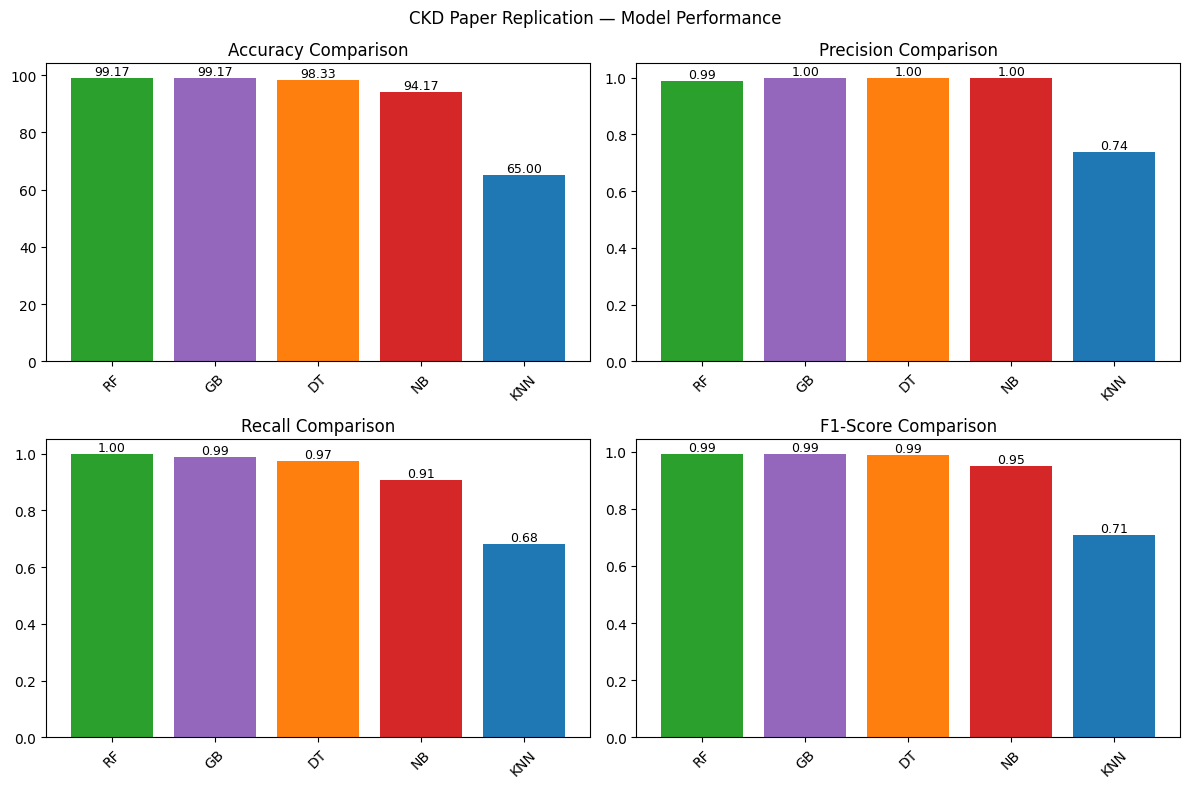

In [ ]:

plot_df = results_leakage_df.copy()

model_colors = {
    "KNN": "#1f77b4",
    "DT": "#ff7f0e",
    "RF": "#2ca02c",
    "NB": "#d62728",
    "GB": "#9467bd"
}

colors = [model_colors[m] for m in plot_df["CLASSIFIERS"]]

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

metrics = [
    ("ACCURACY (%)", "Accuracy Comparison"),
    ("PRECISION", "Precision Comparison"),
    ("RECALL", "Recall Comparison"),
    ("F1-SCORE", "F1-Score Comparison")
]

for ax, (metric, title) in zip(axs.flat, metrics):
    bars = ax.bar(plot_df["CLASSIFIERS"], plot_df[metric], color=colors)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.suptitle("CKD Paper Replication — Model Performance")
plt.tight_layout()
plt.show()

## 9. Export replication results

Run this notebook before the validation comparison. From `src/validation/`, the metrics file is available at `../replication/ckd_replication_metrics.csv`.


In [ ]:
replicated_model_name = "RF"
results_leakage_df.to_csv("ckd_replication_metrics.csv", index=False)
print("Saved replication metrics: ckd_replication_metrics.csv")

Saved replication metrics: ckd_replication_metrics.csv


## Interpretation

The paper-style workflow reproduced very strong performance for the tree-based models, with Random Forest and gradient boosting sharing the highest observed accuracy. Because imputation and encoding were fitted before the data split, these values document the source-style procedure rather than a leakage-controlled estimate. The validation notebook provides the corrected split-first analysis used by the XAI extension.
